# 3.0 · Preprocesamiento

**Proyecto JobPath · Minería de Datos · UNIMINUTO Ibagué · 2026-2**

Fase de **Preparación de los datos** (CRISP-DM). Se limpia, se tipifica y se decide el tratamiento de outliers con evidencia. Los CSV son de solo lectura.

> **Regla:** Los outliers **nunca se eliminan**, solo se ocultan al graficar.

## Alcance

| Sí hace | No hace |
|---|---|
| Diagnóstico de calidad | Escalado/codificación (4.0) |
| Derivadas (Period_Time, duración, isco_mayor) | PCA (4.3) |
| Análisis y decisión de outliers | EDA completo (5.0) |

In [1]:
from pathlib import Path
import sys

def _carpeta_refactor() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'lib' / 'config.py').exists(): return p
        if (p / 'notebooks' / 'refactor' / 'lib' / 'config.py').exists(): return p / 'notebooks' / 'refactor'
    raise RuntimeError('No se encontro la carpeta notebooks/refactor')

RAIZ = _carpeta_refactor()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from lib import calidad, carga, categorias, competencias, config, figuras, periodo

pd.set_option('display.max_columns', 45)
%matplotlib inline
print('Paquete cargado desde:', RAIZ)

Paquete cargado desde: C:\Users\ACER\Desktop\MineriaProtect\MineriaProtect\notebooks\refactor


## 1. Base de análisis: con_outliers

Se parte de **con_outliers** (376.567 filas). El archivo **sin_outliers** se usa como escenario de sensibilidad.

In [2]:
df = carga.leer(config.CON_OUTLIERS)
n_con = carga.contar_filas(config.CON_OUTLIERS)
n_sin = carga.contar_filas(config.SIN_OUTLIERS)
print('Forma:', df.shape)
print(f'con_outliers: {n_con:,} | sin_outliers: {n_sin:,} | diferencia: {n_con-n_sin:,} ({(n_con-n_sin)/n_con*100:.2f}%)')

Forma: (376567, 23)
con_outliers: 376,567 | sin_outliers: 341,090 | diferencia: 35,477 (9.42%)


## 2. Diagnóstico de calidad

In [3]:
print('=== DUPLICADOS ===')
print(calidad.resumen_duplicados(df))
print('\n=== NULOS ===')
display(calidad.resumen_vacios(df))
sin_oficio = competencias.sin_oficio(df)
print('Filas sin oficio (saber_skills):', int(sin_oficio.sum()))

=== DUPLICADOS ===


{'filas': 376567, 'duplicados_exactos': 0, 'resume_id_distintos': 71061, 'experiencias_por_persona_max': 20}

=== NULOS ===


,vacios,porcentaje
sin_tipo,373387,99.16
knowledge,64018,17.00
skills,28306,7.52
occupation_label,28304,7.52
occupation_code,28304,7.52
n_skills_sin_tipo,28304,7.52
n_skills_knowledge,28304,7.52
n_skills_competence,28304,7.52
n_skills_essential,28304,7.52
veces_ese_oficio,28304,7.52


Filas sin oficio (saber_skills): 28304


Los nulos son **estructurales**: coinciden con sin oficio. `university_level` tiene 42.807 filas con "No reportado" (se marca con bandera, no se imputa como 0).

## 3. Period_Time, duración

In [4]:
periodo.validar(df)
df['period_time'] = periodo.crear_period_time(df)
df['duracion'] = periodo.duracion_observada(df)
df['duracion_a_corte'] = periodo.duracion_a_corte(df)
display(df[['start_date','end_date','period_time']].head(3))
print(periodo.resumen_duracion(df))

,start_date,end_date,period_time
0,Q1 2011,Q1 2015,Q1 2011 - Q1 2015
1,Q1 2014,Q1 2015,Q1 2014 - Q1 2015
2,Q1 2015,Q3 2017,Q1 2015 - Q3 2017


{'n_con_fin': 357611, 'n_vigentes': 18956, 'min': 2.0, 'q1': 2.0, 'mediana': 5.0, 'q3': 11.0, 'max': 160.0}


## 4. Categorización y derivadas

In [5]:
df['nivel_ordinal'] = categorias.nivel_ordinal(df)
df['nivel_no_reportado'] = categorias.nivel_no_reportado(df)
df['isco_mayor'] = categorias.isco_mayor(df)
categorias.validar(df)
print('Categorías validadas')
display(categorias.resumen_categorias(df, ['university_level','emparejado','isco_mayor']))

Categorías validadas


,columna,valor,filas,porcentaje
0,university_level,Secondary school,147904,39.28
1,university_level,Bachelor,129507,34.39
2,university_level,Master,54697,14.53
3,university_level,No reportado,42807,11.37
4,university_level,PhD,1652,0.44
5,emparejado,ok,348263,92.48
6,emparejado,unknown,25805,6.85
7,emparejado,rescatado,2499,0.66
8,isco_mayor,5,76375,20.28
9,isco_mayor,3,68222,18.12


## 5. Banderas ESCO (fuente = saber_skills)

In [6]:
df = competencias.agregar_banderas(df)
competencias.validar(df)
display(competencias.resumen_banderas(df))
print()
display(competencias.cruce_banderas(df))
aud = competencias.auditar_falso_positivo(df)
print('\nFalsos positivos (lista vacía vs saber_skills):', aud['falsos_positivos'])

,bandera,valor,filas,porcentaje
0,estado_competencias,con_competencias,348261,92.48
1,estado_competencias,sin_clasificar,28304,7.52
2,estado_competencias,sin_competencias,2,0.00
3,estado_conocimientos,con_conocimientos,312549,83.00
4,estado_conocimientos,sin_conocimientos,35714,9.48
5,estado_conocimientos,sin_clasificar,28304,7.52


estado_conocimientos,con_conocimientos,sin_clasificar,sin_conocimientos,total
estado_competencias,,,,
con_competencias,312547,0,35714,348261
sin_clasificar,0,28304,0,28304
sin_competencias,2,0,0,2
total,312549,28304,35714,376567



Falsos positivos (lista vacía vs saber_skills): 35716


## 6. Outliers de duración: análisis y decisión

Límites IQR: {'q1': 2.0, 'q3': 11.0, 'iqr': 9.0, 'inferior': -11.5, 'superior': 24.5}
Outliers: 35477 (9.42%)


,grupo,filas,media,mediana
0,con outliers,35477,43.50,37.0
1,sin outliers,341090,6.27,5.0
2,total,357611,9.96,5.0


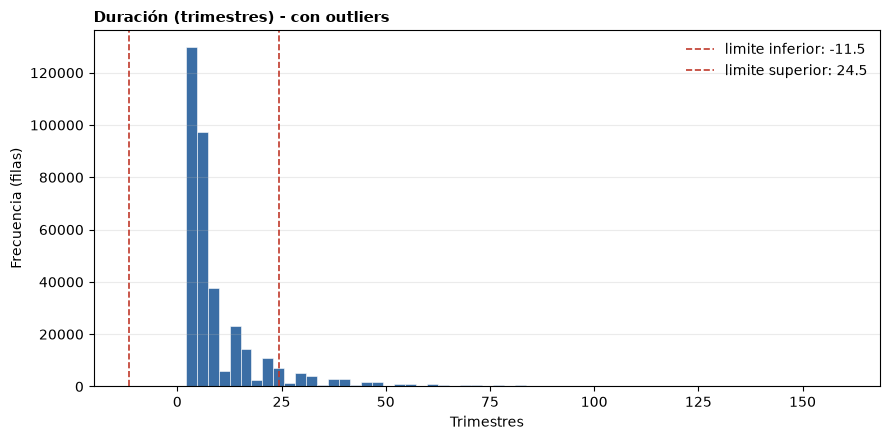

In [7]:
lim = calidad.limites_iqr(df['duracion'])
print('Límites IQR:', lim)
m = calidad.marcar_outliers(df['duracion'])
print('Outliers:', int(m.sum()), f'({100*m.mean():.2f}%)')
display(calidad.impacto_outliers(df, 'duracion'))
fig = figuras.histograma(df['duracion'], 'Duración (trimestres) - con outliers', 'Trimestres', bins=60, limites=lim)
plt.show()

**Decisión:** Base = **con_outliers** (376.567). Los outliers se **conservan**; se **ocultan únicamente al graficar** con `calidad.ocultar()`. `sin_outliers` queda como **análisis de sensibilidad**. Esto cumple "nunca se borran, solo se ocultan".

In [8]:
print('Marco listo para 4.0 | Filas:', len(df))

Marco listo para 4.0 | Filas: 376567
